<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# A row cap is not an inventory total

How does a paging cap change the stock shortfall we can see? Discover an OData entity set and its metadata, retrieve JSON through the real worker, cast its fields in SQL, and compare a capped scan with a complete fixture reference. A request log shows why HTTP-delivered entities and SQL-retained rows can differ.

**All inventory data is invented for this notebook.** A loopback-only, read-only OData v4 fixture serves eight products in fixed three-entity pages. Stock targets are demonstration inputs, not a demand forecast. One product has unknown stock. No enterprise credentials, customer data or real inventory is used.

## Choose the retention cap

`MAX_ROWS` is an integer from **1 to 100**, default **8**. It limits entities retained across pages by the worker, rather than setting the service’s page size. A complete reference uses cap **100**, safely above this tiny fixture. Both queries request the same `ProductID` order. Restart and run all after changing the parameter.

In [1]:
MAX_ROWS = 8  # change to 4 to stop partway through the second three-entity page

In [2]:
import haybarn
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator

from notebook_support import finish, theme
from synthetic_odata import InventoryService

assert type(MAX_ROWS) is int and 1 <= MAX_ROWS <= 100
service = InventoryService()
SERVICE_URL = service.url
connection = haybarn.connect()
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-odata/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-odata/notebooks/pyproject.toml.

## Discover the entity set and declared field types

The literal release location starts a published native worker. `SERVICE_URL` is only the disposable fixture’s local HTTP address. It is not a hidden worker launch command. Discovery and metadata are real worker calls, materialized once. The worker returns entities as raw JSON text; EDM types describe the service, but they do not automatically create typed SQL columns.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
INSTALL json;
LOAD json;
ATTACH 'odata' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-odata@v0.4.0');
CREATE TABLE entity_sets AS SELECT * FROM odata.main.odata_entity_sets('{{SERVICE_URL}}');
CREATE TABLE metadata AS SELECT * FROM odata.main.odata_metadata('{{SERVICE_URL}}');

,Count


In [4]:
%%sql declarations <<
SELECT s.name AS entity_set,m.entity_type,m.property,m.type AS declared_edm_type
FROM entity_sets s CROSS JOIN metadata m WHERE s.name='Products' AND m.entity_type='Product'
ORDER BY m.property;

In [5]:
display(declarations)

,entity_set,entity_type,property,declared_edm_type
0,Products,Product,Category,Edm.String
1,Products,Product,Name,Edm.String
2,Products,Product,ProductID,Edm.Int32
3,Products,Product,Stock,Edm.Int32
4,Products,Product,Target,Edm.Int32


## Follow continuation links, then apply the cap

We use `max_rows`, with no `$top` option. The fixture provides relative `@odata.nextLink` values; the worker follows them against each page URL. `seq` is a zero-based output ordinal, not the product key. The stable `ProductID` ordering makes the capped result a reproducible prefix.

Each API call is materialized with `CREATE TABLE AS SELECT`, so later DataFrame captures do not repeat it. The companion’s phase label only tags its own HTTP audit log; it does not affect rows served.

In [6]:
service.phase = "reference"

In [7]:
%%sql
CREATE TABLE reference_raw AS
SELECT * FROM odata.main.odata_query('{{SERVICE_URL}}','Products',orderby := 'ProductID',max_rows := 100);

,Count


In [8]:
service.phase = "selected"

In [9]:
%%sql
CREATE TABLE selected_raw AS
SELECT * FROM odata.main.odata_query('{{SERVICE_URL}}','Products',orderby := 'ProductID',max_rows := {{MAX_ROWS}});

,Count


## Cast explicitly and preserve unknown stock

`TRY_CAST` makes conversion failures visible as NULL. The stock gap is `max(target − stock, 0)` only when stock is known. The explicit NULL branch matters: a missing measurement must not become zero gap. Summed known gaps are units needed to reach invented targets for observed products, not an order recommendation. A capped scan can also omit entire products or categories.

In [10]:
%%sql
CREATE TABLE products AS
SELECT scenario,seq,try_cast(json_extract_string(entity,'$.ProductID') AS INTEGER) AS product_id,
 json_extract_string(entity,'$.Name') AS product_name,json_extract_string(entity,'$.Category') AS category,
 try_cast(json_extract_string(entity,'$.Stock') AS INTEGER) AS stock,
 try_cast(json_extract_string(entity,'$.Target') AS INTEGER) AS target,
 json_type(entity,'$.Stock') AS stock_json_type
FROM (SELECT 'Complete reference' AS scenario,* FROM reference_raw UNION ALL SELECT 'Selected scan',* FROM selected_raw);
CREATE TABLE gaps AS
SELECT *,CASE WHEN stock IS NULL OR target IS NULL THEN NULL ELSE greatest(target-stock,0) END AS known_gap
FROM products;
CREATE TABLE category_totals AS
WITH r AS(SELECT category,count(*) AS products,count(*) FILTER(WHERE stock IS NULL) AS unknown_stock,
 sum(known_gap) AS known_gap FROM gaps WHERE scenario='Complete reference' GROUP BY category),
 s AS(SELECT category,count(*) AS products,count(*) FILTER(WHERE stock IS NULL) AS unknown_stock,
 sum(known_gap) AS known_gap FROM gaps WHERE scenario='Selected scan' GROUP BY category)
SELECT r.category,r.products AS reference_products,r.unknown_stock AS reference_unknown_stock,r.known_gap AS reference_gap,
 s.products AS selected_products,s.unknown_stock AS selected_unknown_stock,s.known_gap AS selected_gap
FROM r LEFT JOIN s USING(category);

,Count


In [11]:
%%sql retained <<
SELECT seq,product_id,product_name,category,stock,target,known_gap,stock_json_type
FROM gaps WHERE scenario='Selected scan' ORDER BY seq;

In [12]:
display(retained)

,seq,product_id,product_name,category,stock,target,known_gap,stock_json_type
0,0,1,Bolts,Hardware,24,20,0,UBIGINT
1,1,2,Nuts,Hardware,<NA>,15,<NA>,NULL
2,2,3,Tape,Packing,4,12,8,UBIGINT
3,3,4,Boxes,Packing,18,10,0,UBIGINT
4,4,5,Gloves,Safety,2,10,8,UBIGINT
5,5,6,Goggles,Safety,0,6,6,UBIGINT
6,6,7,Labels,Packing,1,9,8,UBIGINT
7,7,8,Washers,Hardware,5,14,9,UBIGINT


In [13]:
%%sql categories <<
SELECT * FROM category_totals ORDER BY category;

,category,reference_products,reference_unknown_stock,reference_gap,selected_products,selected_unknown_stock,selected_gap
0,Hardware,3,1,9.0,3,1,9.0
1,Packing,3,0,16.0,3,0,16.0
2,Safety,2,0,14.0,2,0,14.0


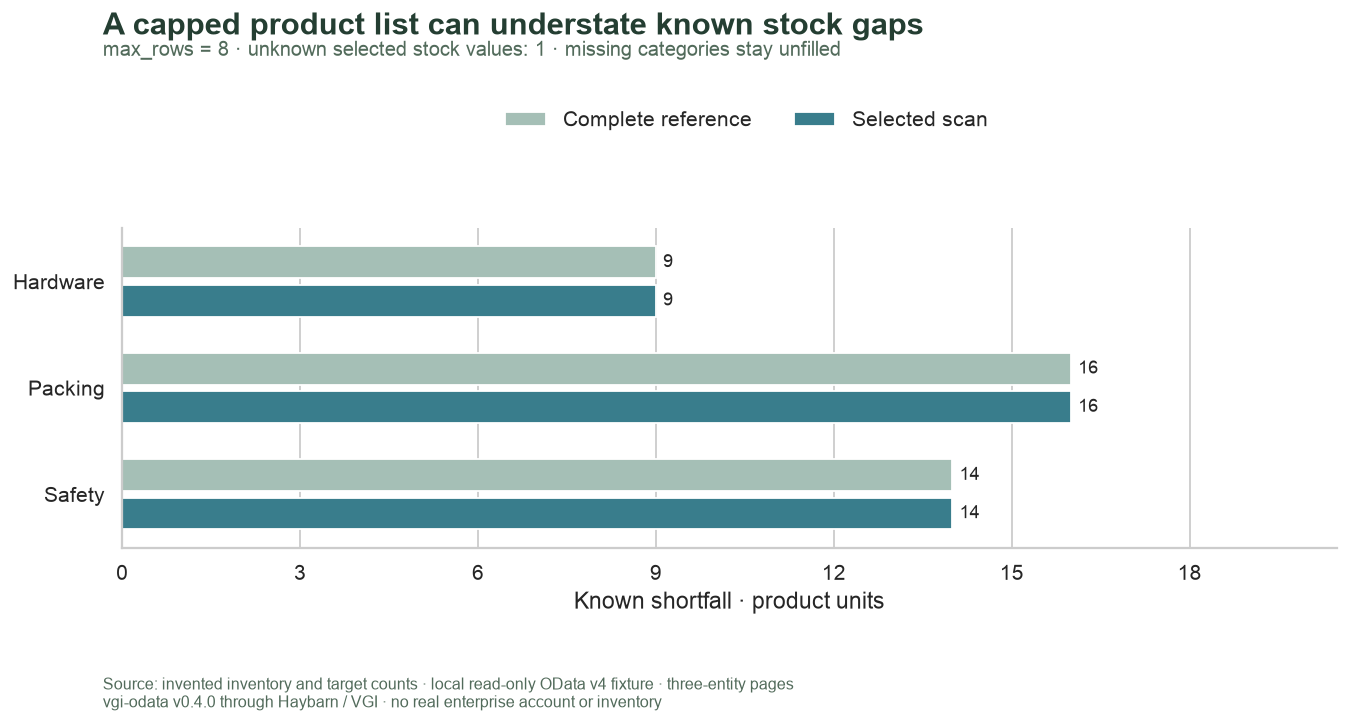

In [14]:
display(categories)
fig, ax = plt.subplots(figsize=(11, 5.6))
y = list(range(len(categories)))
ref = ax.barh([i - 0.18 for i in y], categories.reference_gap, height=0.3, color="#a5bfb6", label="Complete reference")
ax.bar_label(ref, padding=4, fontsize=10)
for i, row in enumerate(categories.itertuples()):
    if pd.notna(row.selected_gap):
        bar = ax.barh(
            i + 0.18, row.selected_gap, height=0.3, color="#397d8c", label="Selected scan" if i == 0 else None
        )
        ax.bar_label(bar, labels=[f"{row.selected_gap:,.0f}"], padding=4, fontsize=10)
    else:
        label = "Not retrieved" if pd.isna(row.selected_products) else "Stock unavailable"
        ax.text(0.2, i + 0.18, label, va="center", color="#9b5738", fontsize=10)
ax.set_yticks(y, categories.category)
ax.set_ylim(len(categories) - 0.5, -0.5)
ax.set_xlim(0, float(categories.reference_gap.max()) * 1.28)
ax.set_xlabel("Known shortfall · product units")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
fig.legend(*ax.get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.55, 0.87), ncol=2, frameon=False)
unknown = int(retained.stock.isna().sum())
finish(
    fig,
    f"gaps-cap-{MAX_ROWS}",
    "A capped product list can understate known stock gaps",
    f"max_rows = {MAX_ROWS} · unknown selected stock values: {unknown} · missing categories stay unfilled",
)

## Inspect what HTTP delivered and SQL kept

This fixture exposes an extra request audit, which a general OData service need not provide and `odata_query` does not return. The log records page offsets, entities served and whether each response advertised another page. SQL summarizes that evidence alongside retained row counts. A cap can stop inside an already fetched page; receiving exactly the cap alone does not prove completeness.

In [15]:
service.save_audit()

In [16]:
%%sql
CREATE TABLE request_log AS SELECT * FROM read_json('validation/request_audit.json');
CREATE TABLE paging AS
SELECT CASE phase WHEN 'reference' THEN 'Complete reference' ELSE 'Selected scan' END AS scenario,
 count(*) AS http_pages,sum(entities_served) AS delivered_entities,arg_max(has_next,page_offset) AS last_page_has_next
FROM request_log GROUP BY phase;
CREATE TABLE scan_totals AS
SELECT p.*,g.retained_products,g.unknown_stock,g.known_gap,p.delivered_entities-g.retained_products AS delivered_not_retained
FROM paging p JOIN(
 SELECT scenario,count(*) AS retained_products,count(*) FILTER(WHERE stock IS NULL) AS unknown_stock,sum(known_gap) AS known_gap
 FROM gaps GROUP BY scenario)g USING(scenario);

,Count


In [17]:
%%sql totals <<
SELECT * FROM scan_totals ORDER BY CASE scenario WHEN 'Complete reference' THEN 0 ELSE 1 END;

,scenario,http_pages,delivered_entities,last_page_has_next,retained_products,unknown_stock,known_gap,delivered_not_retained
0,Complete reference,3,8.0,False,8,1,39.0,0.0
1,Selected scan,3,8.0,False,8,1,39.0,0.0


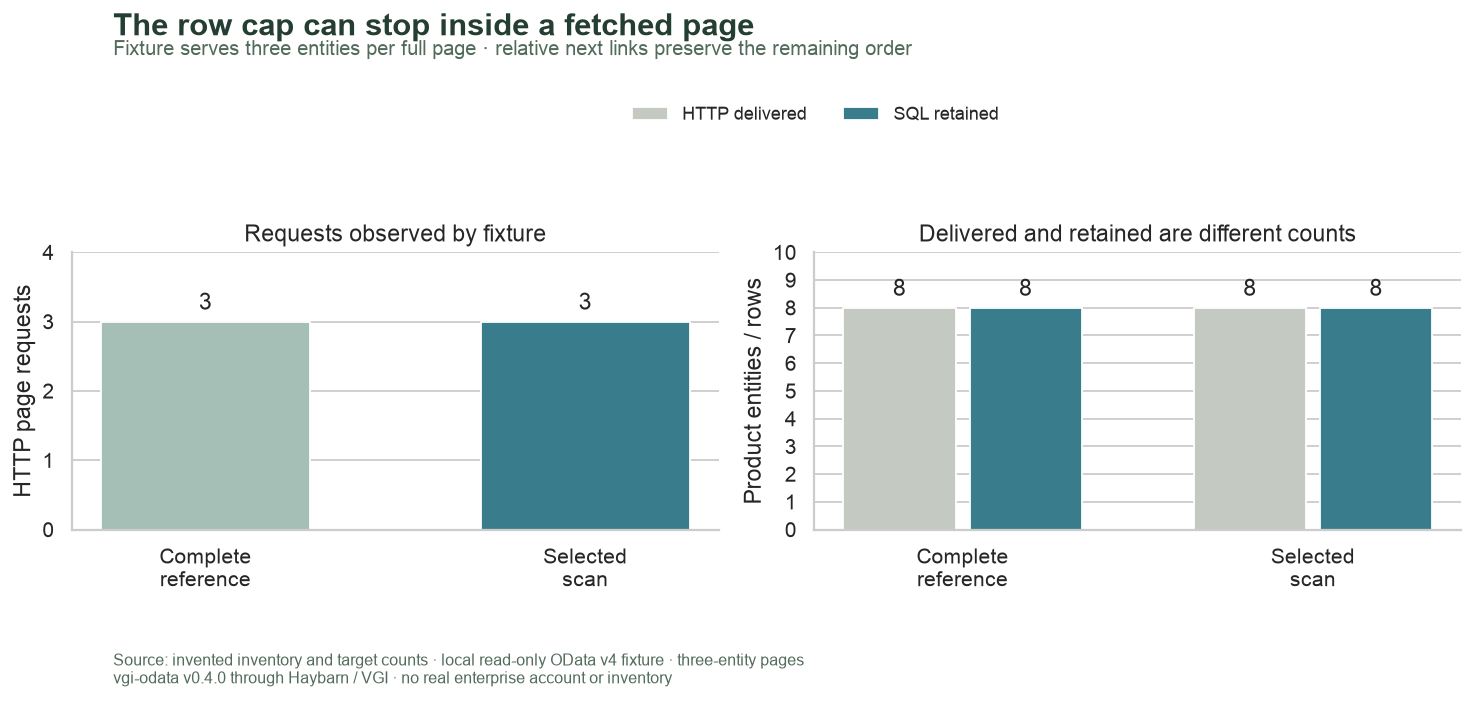

In [18]:
display(totals)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.4))
x = list(range(len(totals)))
bars = axes[0].bar(x, totals.http_pages, color=["#a5bfb6", "#397d8c"], width=0.55)
axes[0].bar_label(bars, padding=4)
axes[0].set_ylabel("HTTP page requests")
axes[0].set_title("Requests observed by fixture")
axes[0].set_ylim(0, float(totals.http_pages.max()) + 1)
for col, offset, color, label in [
    ("delivered_entities", -0.18, "#c4c9c2", "HTTP delivered"),
    ("retained_products", 0.18, "#397d8c", "SQL retained"),
]:
    bars = axes[1].bar([i + offset for i in x], totals[col], width=0.32, color=color, label=label)
    axes[1].bar_label(bars, padding=4)
axes[1].set_ylabel("Product entities / rows")
axes[1].set_title("Delivered and retained are different counts")
axes[1].set_ylim(0, float(totals.delivered_entities.max()) + 2)
for ax in axes:
    ax.set_xticks(x, ["Complete\nreference", "Selected\nscan"])
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(axis="x", visible=False)
fig.legend(
    *axes[1].get_legend_handles_labels(),
    loc="upper center",
    bbox_to_anchor=(0.55, 0.87),
    ncol=2,
    frameon=False,
    fontsize=10,
)
finish(
    fig,
    f"paging-cap-{MAX_ROWS}",
    "The row cap can stop inside a fetched page",
    "Fixture serves three entities per full page · relative next links preserve the remaining order",
)

In [19]:
selected = totals[totals.scenario == "Selected scan"].iloc[0]
reference = totals[totals.scenario == "Complete reference"].iloc[0]
display(
    Markdown(
        f"The selected query made **{int(selected.http_pages)} page requests**, receiving "
        f"**{int(selected.delivered_entities)} entities** and retaining **{int(selected.retained_products)} rows**. "
        f"Its known shortfall is **{int(selected.known_gap)} units**, "
        f"compared with **{int(reference.known_gap)} units** in the complete reference. "
        f"Unknown selected stock values: **{int(selected.unknown_stock)}**; these are excluded from known totals. "
        "The reference and request log establish coverage for this fixture; "
        "a raw capped result alone does not certify a complete service scan."
    )
)

The selected query made **3 page requests**, receiving **8 entities** and retaining **8 rows**. Its known shortfall is **39 units**, compared with **39 units** in the complete reference. Unknown selected stock values: **1**; these are excluded from known totals. The reference and request log establish coverage for this fixture; a raw capped result alone does not certify a complete service scan.

## Validate identity, paging and NULL accounting

Use product IDs as keys, compare the retained prefix with the complete reference, and reconcile request delivery with SQL retention. Fixture completeness is checked against its bundled input inventory, not inferred from the cap. These invariants accept any supported `MAX_ROWS`.

In [20]:
%%sql checks <<
SELECT 'discovery exposes Products' AS check_name,count(*)=1 AS passed FROM entity_sets WHERE name='Products'
UNION ALL SELECT 'EDM metadata declares all five product fields',count(*)=5 AND count(DISTINCT property)=5 FROM metadata WHERE entity_type='Product'
UNION ALL SELECT 'complete reference covers the fixture IDs',count(*)=0 FROM(
 (SELECT product_id FROM products WHERE scenario='Complete reference' EXCEPT SELECT ProductID FROM read_json('fixtures/products.json'))
 UNION ALL(SELECT ProductID FROM read_json('fixtures/products.json') EXCEPT SELECT product_id FROM products WHERE scenario='Complete reference'))
UNION ALL SELECT 'product keys are unique within each scan',count(*)=count(DISTINCT(scenario,product_id)) FROM products
UNION ALL SELECT 'row count follows the cap',
 (SELECT count(*) FROM selected_raw)=least({{MAX_ROWS}},(SELECT count(*) FROM reference_raw))
UNION ALL SELECT 'selected raw entities equal the reference prefix',count(*)=0 FROM(
 (SELECT * FROM selected_raw EXCEPT ALL SELECT * FROM reference_raw WHERE seq<{{MAX_ROWS}})
 UNION ALL(SELECT * FROM reference_raw WHERE seq<{{MAX_ROWS}} EXCEPT ALL SELECT * FROM selected_raw))
UNION ALL SELECT 'known stock and targets cast without invalid negatives',bool_and(product_id IS NOT NULL AND target>=0 AND (stock>=0 OR stock_json_type='NULL')) FROM products
UNION ALL SELECT 'unknown stock remains unknown gap',coalesce(bool_and(known_gap IS NULL),true) FROM gaps WHERE stock IS NULL
UNION ALL SELECT 'known gaps use the explicit nonnegative difference',bool_and(known_gap=greatest(target-stock,0)) FROM gaps WHERE stock IS NOT NULL
UNION ALL SELECT 'each page offset is fetched once per scan',count(*)=count(DISTINCT(phase,page_offset)) FROM request_log
UNION ALL SELECT 'delivered entities cover retained rows',bool_and(delivered_entities>=retained_products) FROM scan_totals
UNION ALL SELECT 'complete reference reaches a terminal page',bool_and(NOT last_page_has_next AND delivered_entities=retained_products) FROM scan_totals WHERE scenario='Complete reference';

In [21]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
display(
    Markdown(
        f"All **{len(checks)} checks** pass. Missing values, missing rows and paging limits have separate accounting."
    )
)

,check_name,passed
0,discovery exposes Products,True
1,EDM metadata declares all five product fields,True
2,complete reference covers the fixture IDs,True
3,product keys are unique within each scan,True
4,row count follows the cap,True
5,selected raw entities equal the reference prefix,True
6,known stock and targets cast without invalid n...,True
7,unknown stock remains unknown gap,True
8,known gaps use the explicit nonnegative differ...,True
9,each page offset is fetched once per scan,True


All **12 checks** pass. Missing values, missing rows and paging limits have separate accounting.

## Try one change

Change `MAX_ROWS` from **8** to **4**, restart and run all. Predict that the worker fetches a second three-entity page but retains only enough rows to reach four. Compare the page audit, omitted categories and known stock gap. The unknown stock value should remain NULL; no inventory values or targets change. Restore **8** for the saved default.

This fixture does not model concurrent inventory updates, authentication, server-side filtering or unstable ordering. On real services, choose a stable key order and establish completeness separately before interpreting a capped aggregate as a total.

In [22]:
connection.close()
service.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>